# Detecting ChatGPT-Generated Text — full project notebook

**Course:** AI Essentials: Theory and Applications · **Stage:** Midterm (project proposal & initial implementation)

**Task:** given an answer to a question, decide whether it was written by a **human** or by **ChatGPT**.

| Part | What happens |
|---|---|
| 1. Setup | Libraries and settings |
| 2. Load the data | Read the HC3 dataset into one table |
| 3. Explore the data | Topics, classes, text length |
| 4. Data quality | Empty answers, error messages, duplicates |
| 5. The "trick" in the data | Formatting differences that let a model cheat |
| 6. Cleaning | Remove the trick and bad rows |
| 7. Balanced data and split | One human + one ChatGPT answer per question; train / validation / test |
| 8. Model 0 — length only | The simplest baseline |
| 9. Model 1 — TF-IDF + logistic regression | Classical machine learning |
| 10. Model 2 — neural network in PyTorch | A small network trained from scratch |
| 11. Model 3 — GPT-2 perplexity | A language model, no training |
| 12. Results | All models side by side |
| 13. Test on unseen topics | Does the detector generalise? |
| 14. Extra — writing style | How ChatGPT style differs from human style |

## 1. Setup

### 1.1 Import libraries
**What this cell does:** loads the tools we use: pandas (tables), numpy (numbers), matplotlib (charts), scikit-learn (classical ML), PyTorch (neural networks) and transformers (GPT-2).

In [1]:
import os, re, json, time, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

import torch
import torch.nn as nn

warnings.filterwarnings('ignore')
os.environ['HF_HUB_DISABLE_PROGRESS_BARS'] = '1'
os.environ['TRANSFORMERS_VERBOSITY'] = 'error'

### 1.2 Settings
**What this cell does:** fixes the random seed, the folder with the data and the chart colours.

**Why:** the same seed (42) gives exactly the same results every time the notebook is run — results are reproducible.

In [2]:
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

DATA_FOLDER = Path('../data/raw')
TOPICS = ['finance', 'medicine', 'open_qa', 'reddit_eli5', 'wiki_csai']

BLUE, ORANGE = '#2a78d6', '#e8833a'
plt.rcParams['figure.dpi'] = 110

## 2. Load the data
**HC3** (Human ChatGPT Comparison Corpus, Guo et al., 2023) is downloaded from Hugging Face by `scripts/download_data.py`.
There is one file per topic. Each line of a file is one question with a list of human answers and a list of ChatGPT answers.

### 2.1 Look at one raw line
**What this cell does:** opens the finance file and prints the first question with its answers, exactly as stored.

**Why:** to see the original format before we change anything.

In [3]:
with open(DATA_FOLDER / 'finance.jsonl', encoding='utf-8') as f:
    first_line = json.loads(f.readline())

print('Question:', first_line['question'])
print('\nHuman answer:', first_line['human_answers'][0][:300])
print('\nChatGPT answer:', first_line['chatgpt_answers'][0][:300])

Question: Historical P/E ratios of small-cap vs. large-cap stocks?

Human answer: There is most likely an error in the WSJ's data.  Yahoo! Finance reports the P/E on the Russell 2000 to be 15 as of 8/31/11 and S&P 500 P/E to be 13 (about the same as WSJ). Good catch, though!  E-mail WSJ, perhaps they will be grateful.

ChatGPT answer: Historical price-to-earnings (P/E) ratios for small-cap and large-cap stocks can vary significantly over time and may not be directly comparable due to the different characteristics of these two categories of stocks.Small-cap stocks, which are defined as stocks with a market capitalization of less t


### 2.2 Read all files into one table
**What this cell does:** goes through the 5 files and creates one row per answer, with the topic, a question id, the text and the label (`human` or `chatgpt`).

In [4]:
rows = []
for topic in TOPICS:
    with open(DATA_FOLDER / f'{topic}.jsonl', encoding='utf-8') as f:
        for number, line in enumerate(f):
            item = json.loads(line)
            question_id = f'{topic}_{number}'
            for answer in item['human_answers']:
                rows.append([topic, question_id, answer or '', 'human'])
            for answer in item['chatgpt_answers']:
                rows.append([topic, question_id, answer or '', 'chatgpt'])

df = pd.DataFrame(rows, columns=['topic', 'question_id', 'text', 'label'])
print('Questions:', df.question_id.nunique())
print('Answers:  ', len(df))
df.head()

Questions: 24322
Answers:   85449


,topic,question_id,text,label
0,finance,finance_0,There is most likely an error in the WSJ's dat...,human
1,finance,finance_0,Historical price-to-earnings (P/E) ratios for ...,chatgpt
2,finance,finance_1,I know this question has a lot of answers alre...,human
3,finance,finance_1,Co-signing a personal loan for a friend or fam...,chatgpt
4,finance,finance_2,If you pay it off before the cycle closes it w...,human


## 3. Explore the data

### 3.1 Answers per topic and author
**What this cell does:** counts how many human and ChatGPT answers each topic has.

**Why:** to see whether the classes are balanced.

In [5]:
counts = pd.crosstab(df.topic, df.label)
counts

label,chatgpt,human
topic,,
finance,4503,3933
medicine,1337,1248
open_qa,3561,1187
reddit_eli5,16660,51336
wiki_csai,842,842


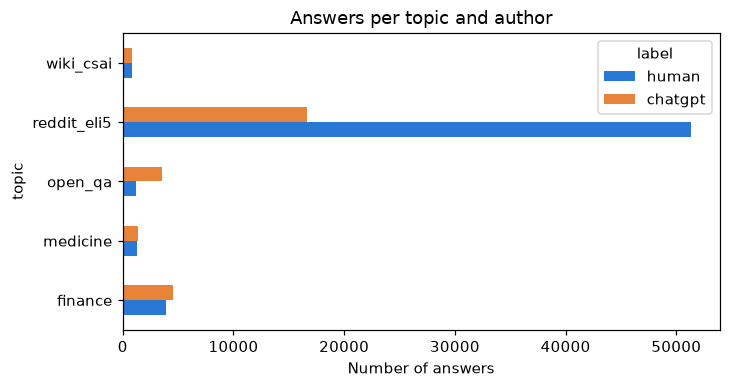

In [6]:
counts[['human', 'chatgpt']].plot.barh(color=[BLUE, ORANGE], figsize=(7, 3.5))
plt.xlabel('Number of answers')
plt.title('Answers per topic and author')
plt.show()

**Observation:** Reddit (`reddit_eli5`) has most of the data and three times more human answers than ChatGPT answers.

### 3.2 Text length
**What this cell does:** counts the words in every answer and shows the median length per topic and author.

In [7]:
df['n_words'] = df.text.str.split().str.len()
df.groupby(['topic', 'label']).n_words.median().unstack()

label,chatgpt,human
topic,,
finance,205.0,129.0
medicine,184.0,74.0
open_qa,106.0,27.0
reddit_eli5,173.0,82.0
wiki_csai,187.5,166.0


**Observation:** ChatGPT answers are usually longer and more uniform in length than human answers.

## 4. Data quality

### 4.1 Empty answers
**What this cell does:** counts answers that contain no text.

In [8]:
is_empty = df.text.str.strip() == ''
print('Empty answers:', is_empty.sum())

Empty answers: 18


### 4.2 Error messages instead of answers
**What this cell does:** finds ChatGPT "answers" that are actually server error messages (for example "Too many requests").

**Why:** these are not real answers and must be removed.

In [9]:
is_error = df.text.str.contains('There was an error generating a response|Too many requests')
print('Error messages:', is_error.sum())
print(df.text[is_error].iloc[0][:120])

Error messages: 100
!Your authentication token has expired. Please try signing in again.There was an error generating a response


### 4.3 Duplicates
**What this cell does:** counts texts that appear more than once.

**Why:** the same text in training and in testing would make the test too easy.

In [10]:
print('Duplicate texts:', df.duplicated('text').sum())

Duplicate texts: 6117


## 5. The "trick" in the data
Human answers come from older datasets where the text was split into tokens, so they contain **spaces before punctuation**
(`word , word`). ChatGPT answers do not. This has nothing to do with who wrote the text — but a model could learn it.

### 5.1 How often each author has a space before punctuation
**What this cell does:** checks every answer for the pattern "space + punctuation mark" and shows the percentage for humans and for ChatGPT.

In [11]:
has_space_before_punct = df.text.str.contains(r' [,.!?;:]')
df.assign(pattern=has_space_before_punct).groupby('label').pattern.mean() * 100

label
chatgpt     0.275062
human      88.813924
Name: pattern, dtype: float64

### 5.2 A one-line "detector" without any AI
**What this cell does:** uses only one rule — *if there is a space before punctuation, say "human", otherwise "ChatGPT"* — on all valid answers, and measures how often it is right.

**Why:** if a rule this simple works, a machine-learning model could also cheat in the same way.

In [12]:
valid = df[~is_empty & ~is_error].drop_duplicates('text')

def formatting_rule(texts):
    return np.where(texts.str.contains(r' [,.!?;:]'), 'human', 'chatgpt')

rule_accuracy_raw = (formatting_rule(valid.text) == valid.label).mean()
print(f'Accuracy of the one-line rule on raw data: {rule_accuracy_raw:.1%}')

Accuracy of the one-line rule on raw data: 91.8%


## 6. Cleaning

### 6.1 Cleaning rules
**What this cell does:** defines the formatting rules. Each rule is a pair: *what to find* (a regular expression) and *what to put instead*.

**Why:** the rules restore normal writing so that human and ChatGPT texts look the same technically. They are applied to **both** classes.

In [13]:
CLEANING_RULES = [
    (r'\\n', ' '),                                  # literal "\n" characters        -> space
    (r'\s+', ' '),                                  # line breaks / double spaces     -> one space
    (r'([a-z0-9\)])\.([A-Z])', r'\1. \2'),          # "end.Next"                      -> "end. Next"
    (r'\s+([,.!?;:%])', r'\1'),                     # "word , word"                   -> "word, word"
    (r"\s+(n't|'s|'re|'ve|'ll|'d|'m)\b", r'\1'),    # "do n't"                        -> "don't"
    (r'\(\s+', '('),                                # "( x"                           -> "(x"
    (r'\s+\)', ')'),                                # "x )"                           -> "x)"
    (r'(\w)\s+-\s+(\w)', r'\1-\2'),                 # "well - known"                  -> "well-known"
    (r'"\s+([^"]*?)\s+"', r'"\1"'),                 # '" quote "'                     -> '"quote"'
    (r'\$\s+(\d)', r'$\1'),                         # "$ 5"                           -> "$5"
]

def clean_text(text):
    for pattern, replacement in CLEANING_RULES:
        text = re.sub(pattern, replacement, text)
    return text.strip()

### 6.2 Example: before and after cleaning
**What this cell does:** applies the cleaning to one tokenized human answer to show the effect.

In [14]:
example = "Basically there are many categories of \" Best Seller \" . You 're still a best seller , and do n't forget it ."
print('BEFORE:', example)
print('AFTER: ', clean_text(example))

BEFORE: Basically there are many categories of " Best Seller " . You 're still a best seller , and do n't forget it .
AFTER:  Basically there are many categories of "Best Seller". You're still a best seller, and don't forget it.


### 6.3 Clean the whole dataset step by step
**What this cell does:** removes empty answers and error messages, cleans every text, removes very short answers and duplicates, and records how many answers remain after each step.

In [15]:
log = [('Original data', len(df))]

data = df[~is_empty]
log.append(('1. Remove empty answers', len(data)))

data = data[~is_error[~is_empty]].copy()
log.append(('2. Remove error messages', len(data)))

data['text_clean'] = data.text.apply(clean_text)
data['n_words'] = data.text_clean.str.split().str.len()
log.append(('3. Clean the formatting', len(data)))

data = data[data.n_words >= 5]
log.append(('4. Remove answers shorter than 5 words', len(data)))

data = data.drop_duplicates('text_clean')
log.append(('5. Remove duplicates', len(data)))

pd.DataFrame(log, columns=['step', 'answers left'])

,step,answers left
0,Original data,85449
1,1. Remove empty answers,85431
2,2. Remove error messages,85331
3,3. Clean the formatting,85331
4,4. Remove answers shorter than 5 words,85316
5,5. Remove duplicates,79304


### 6.4 Does the trick still work after cleaning?
**What this cell does:** runs the same one-line rule on the cleaned texts.

In [16]:
rule_accuracy_clean = (formatting_rule(data.text_clean) == data.label).mean()
print(f'Rule on raw text:     {(formatting_rule(data.text) == data.label).mean():.1%}')
print(f'Rule on cleaned text: {rule_accuracy_clean:.1%}')

Rule on raw text:     91.8%
Rule on cleaned text: 33.1%


**Result:** after cleaning the rule is worse than a coin flip — the trick is removed.

## 7. Balanced data and train / validation / test split

### 7.1 One human and one ChatGPT answer per question
**What this cell does:** for every question picks one random human answer and one random ChatGPT answer, and keeps only questions that have both.

**Why:** both classes become exactly equal in size, and both answer the same questions — the topic cannot give the answer away.

In [17]:
pairs = data.groupby(['question_id', 'label']).sample(n=1, random_state=SEED)

labels_per_question = pairs.groupby('question_id').label.transform('nunique')
pairs = pairs[labels_per_question == 2].reset_index(drop=True)

pairs['y'] = (pairs.label == 'chatgpt').astype(int)     # 1 = ChatGPT, 0 = human
print('Questions:', pairs.question_id.nunique(), '  Answers:', len(pairs))
pairs.label.value_counts()

Questions: 21913   Answers: 43826


label
chatgpt    21913
human      21913
Name: count, dtype: int64

### 7.2 Split by question
**What this cell does:** puts 80% of the questions into the training set, 10% into validation and 10% into the test set.

**Why:** both answers to the same question always go to the same set, so the model is tested on questions it has never seen.

In [18]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, rest_idx = next(splitter.split(pairs, groups=pairs.question_id))
rest = pairs.iloc[rest_idx]

splitter2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=SEED)
val_idx, test_idx = next(splitter2.split(rest, groups=rest.question_id))

train = pairs.iloc[train_idx]
val = rest.iloc[val_idx]
test = rest.iloc[test_idx]
print('Train:', len(train), '  Validation:', len(val), '  Test:', len(test))

Train: 35060   Validation: 4382   Test: 4384


### 7.3 Evaluation function
**What this cell does:** a small helper that compares the model's predictions with the true labels and stores Accuracy, F1 and ROC-AUC.

**Why:** all models are measured in exactly the same way.

In [19]:
results = {}

def evaluate(model_name, true_labels, predicted_probability, threshold=0.5):
    predicted_labels = (predicted_probability >= threshold).astype(int)
    results[model_name] = {
        'Accuracy': accuracy_score(true_labels, predicted_labels),
        'F1': f1_score(true_labels, predicted_labels),
        'ROC-AUC': roc_auc_score(true_labels, predicted_probability),
    }
    print(model_name, {k: round(v, 3) for k, v in results[model_name].items()})

**Metrics in simple words**
* **Accuracy** — share of correct answers.
* **F1** — balance between *precision* (how many texts flagged as ChatGPT really are ChatGPT) and *recall* (how many ChatGPT texts we found).
* **ROC-AUC** — how well the model ranks ChatGPT texts above human texts (0.5 = random, 1 = perfect).

## 8. Model 0 — length only (baseline)

### 8.1 Train on text length
**What this cell does:** trains a logistic regression that sees only one number: the length of the text.

**Why:** this is the minimum level. Any real detector must be better than this.

In [20]:
def length_feature(table):
    return np.log1p(table[['n_words']].values)

length_model = LogisticRegression()
length_model.fit(length_feature(train), train.y)

evaluate('Length only', test.y, length_model.predict_proba(length_feature(test))[:, 1])

Length only {'Accuracy': 0.752, 'F1': 0.771, 'ROC-AUC': 0.766}


## 9. Model 1 — TF-IDF + logistic regression (classical machine learning)
**TF-IDF** turns each text into numbers: a word gets a high weight if it is frequent in this text but rare in other texts.
**Logistic regression** then learns which words point to ChatGPT and which point to a human.

### 9.1 Turn texts into TF-IDF numbers
**What this cell does:** builds the vocabulary of words and word pairs on the training texts and converts every text into a vector.

In [21]:
vectorizer = TfidfVectorizer(ngram_range=(1, 2),            # single words and pairs of words
                             min_df=3,                      # ignore very rare words
                             max_features=100_000,          # keep the 100,000 most useful
                             sublinear_tf=True,
                             token_pattern=r"(?u)\b\w+\b|[^\w\s]")

X_train = vectorizer.fit_transform(train.text_clean)
X_test = vectorizer.transform(test.text_clean)
print('Texts x features:', X_train.shape)

Texts x features: (35060, 100000)


### 9.2 Train the classifier and test it
**What this cell does:** trains the logistic regression on the training vectors and evaluates it on the test set.

In [22]:
tfidf_model = LogisticRegression(C=4, max_iter=2000)
tfidf_model.fit(X_train, train.y)

evaluate('TF-IDF + logistic regression', test.y, tfidf_model.predict_proba(X_test)[:, 1])

TF-IDF + logistic regression {'Accuracy': 0.987, 'F1': 0.987, 'ROC-AUC': 0.999}


### 9.3 Which words does the model use?
**What this cell does:** shows the words with the strongest weights towards ChatGPT and towards human.

**Why:** to check that the model learned real style, not formatting.

In [23]:
words = np.array(vectorizer.get_feature_names_out())
weights = tfidf_model.coef_[0]
order = np.argsort(weights)
pd.DataFrame({'→ ChatGPT': words[order[-10:][::-1]], '→ human': words[order[:10]]})

,→ ChatGPT,→ human
0,. it,.
1,important,i
2,", which",/
3,important to,*
4,or,;
5,. this,)
6,and,(
7,", including",. .
8,help,url_0
9,", the",you


## 10. Model 2 — neural network in PyTorch
A small network trained from scratch: each word becomes a vector of 64 numbers (an **embedding**),
the vectors of a text are averaged, and two layers decide *human* or *ChatGPT*.

### 10.1 Split texts into words
**What this cell does:** a function that lower-cases a text and cuts it into words and punctuation marks (at most 400 per text).

In [24]:
def split_into_words(text):
    words = re.findall(r"[a-z0-9']+|[.,!?;:]", text.lower())
    return words[:400]

print(split_into_words("ChatGPT can't write like me, can it?"))

['chatgpt', "can't", 'write', 'like', 'me', ',', 'can', 'it', '?']


### 10.2 Build the vocabulary
**What this cell does:** counts all words in the training texts and gives each of the 30,000 most frequent words a number. Number 0 means "unknown word".

In [25]:
word_counts = Counter()
for text in train.text_clean:
    word_counts.update(split_into_words(text))

vocabulary = {}
for position, (word, count) in enumerate(word_counts.most_common(30_000)):
    if count >= 2:
        vocabulary[word] = position + 1

print('Vocabulary size:', len(vocabulary))

Vocabulary size: 30000


### 10.3 Turn texts into numbers
**What this cell does:** replaces every word by its number. PyTorch needs all texts in one long list plus the position where each text starts (`offsets`).

In [26]:
def texts_to_numbers(texts):
    all_ids, offsets = [], []
    for text in texts:
        offsets.append(len(all_ids))
        ids = [vocabulary.get(word, 0) for word in split_into_words(text)]
        all_ids.extend(ids or [0])
    return torch.tensor(all_ids), torch.tensor(offsets)

### 10.4 Define the network
**What this cell does:** describes the network: an embedding layer (64 numbers per word, averaged over the text), then a hidden layer of 64 neurons with ReLU and dropout, then one output number.

In [27]:
class TextClassifier(nn.Module):
    def __init__(self, vocabulary_size, embedding_size=64):
        super().__init__()
        self.embedding = nn.EmbeddingBag(vocabulary_size + 1, embedding_size, mode='mean')
        self.layers = nn.Sequential(
            nn.Linear(embedding_size, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 1),
        )

    def forward(self, word_ids, offsets):
        text_vector = self.embedding(word_ids, offsets)
        return self.layers(text_vector).squeeze(-1)

### 10.5 Prediction function
**What this cell does:** runs the network on many texts (512 at a time) and turns the output into a probability between 0 and 1 (sigmoid).

In [28]:
def predict_probability(model, texts, batch_size=512):
    model.eval()
    probabilities = []
    with torch.no_grad():
        for start in range(0, len(texts), batch_size):
            word_ids, offsets = texts_to_numbers(texts[start:start + batch_size])
            probabilities.append(torch.sigmoid(model(word_ids, offsets)))
    return torch.cat(probabilities).numpy()

### 10.6 Train the network
**What this cell does:** trains for 6 epochs (6 passes over the training data) in batches of 64 texts. After each epoch it checks the validation set and remembers the best version of the network.

**Why:** the loss function (binary cross-entropy) measures the error; the Adam optimiser changes the weights to reduce it.

In [29]:
torch.manual_seed(SEED)
network = TextClassifier(len(vocabulary))
optimizer = torch.optim.Adam(network.parameters(), lr=3e-3)
loss_function = nn.BCEWithLogitsLoss()

train_texts = train.text_clean.tolist()
train_labels = torch.tensor(train.y.values, dtype=torch.float32)
history = []
best_auc, best_weights = 0, None

for epoch in range(1, 7):
    network.train()
    shuffled = torch.randperm(len(train_texts))
    total_loss = 0
    for start in range(0, len(shuffled), 64):
        batch = shuffled[start:start + 64]
        word_ids, offsets = texts_to_numbers([train_texts[i] for i in batch])
        loss = loss_function(network(word_ids, offsets), train_labels[batch])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(batch)

    val_auc = roc_auc_score(val.y, predict_probability(network, val.text_clean.tolist()))
    history.append((epoch, total_loss / len(shuffled), val_auc))
    print(f'epoch {epoch}: training loss = {total_loss / len(shuffled):.4f}   validation AUC = {val_auc:.4f}')
    if val_auc > best_auc:
        best_auc = val_auc
        best_weights = {name: value.clone() for name, value in network.state_dict().items()}

epoch 1: training loss = 0.2593   validation AUC = 0.9851


epoch 2: training loss = 0.0989   validation AUC = 0.9885


epoch 3: training loss = 0.0521   validation AUC = 0.9886


epoch 4: training loss = 0.0269   validation AUC = 0.9880


epoch 5: training loss = 0.0126   validation AUC = 0.9876


epoch 6: training loss = 0.0071   validation AUC = 0.9867


### 10.7 Training curves
**What this cell does:** plots the training loss (should go down) and the validation AUC (should go up, then stop improving).

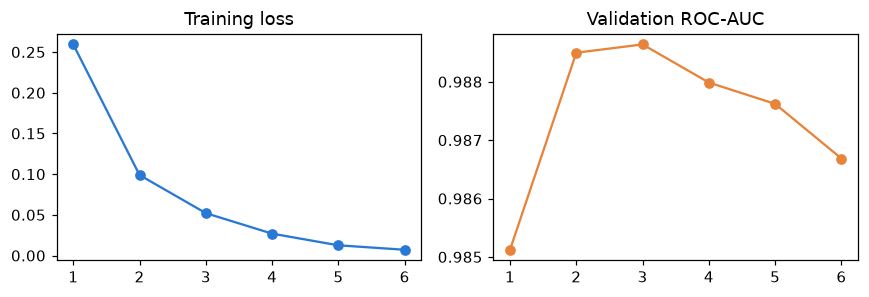

In [30]:
history_table = pd.DataFrame(history, columns=['epoch', 'loss', 'val_auc'])
fig, axes = plt.subplots(1, 2, figsize=(8, 2.8))
axes[0].plot(history_table.epoch, history_table.loss, marker='o', color=BLUE); axes[0].set_title('Training loss')
axes[1].plot(history_table.epoch, history_table.val_auc, marker='o', color=ORANGE); axes[1].set_title('Validation ROC-AUC')
plt.tight_layout(); plt.show()

### 10.8 Test the best network
**What this cell does:** loads the best version (chosen on validation) and evaluates it on the test set.

In [31]:
network.load_state_dict(best_weights)
evaluate('PyTorch neural network', test.y, predict_probability(network, test.text_clean.tolist()))

PyTorch neural network {'Accuracy': 0.953, 'F1': 0.953, 'ROC-AUC': 0.99}


## 11. Model 3 — GPT-2 perplexity (no training)
**Perplexity** shows how "surprised" a language model is by a text. ChatGPT chooses very probable words,
so its text is *more predictable* for another language model → **lower perplexity**. We use GPT-2 and train nothing.

### 11.1 Load GPT-2
**What this cell does:** downloads the small GPT-2 model (124 million parameters) and its tokenizer.

In [32]:
from transformers import AutoTokenizer, AutoModelForCausalLM
from transformers.utils import logging as hf_logging
hf_logging.disable_progress_bar()

gpt2_tokenizer = AutoTokenizer.from_pretrained('openai-community/gpt2')
gpt2 = AutoModelForCausalLM.from_pretrained('openai-community/gpt2').eval()

### 11.2 Perplexity function
**What this cell does:** gives the first 128 tokens of a text to GPT-2, takes its average error (loss) and converts it to perplexity = exp(loss).

In [33]:
def perplexity(text):
    tokens = gpt2_tokenizer(text, return_tensors='pt', truncation=True, max_length=128)
    with torch.no_grad():
        loss = gpt2(**tokens, labels=tokens['input_ids']).loss
    return float(torch.exp(loss))

print('Human example:  ', round(perplexity(test[test.y == 0].text_clean.iloc[0]), 1))
print('ChatGPT example:', round(perplexity(test[test.y == 1].text_clean.iloc[0]), 1))

Human example:   69.1


ChatGPT example: 12.1


### 11.3 Compute perplexity on samples
**What this cell does:** computes perplexity for 300 validation texts and 800 test texts (half human, half ChatGPT).

**Why:** GPT-2 runs on the processor (no GPU), so we use a sample to keep it fast (it still takes several minutes on a laptop).

In [34]:
val_sample = val.groupby('y').sample(n=150, random_state=SEED)
test_sample = test.groupby('y').sample(n=400, random_state=SEED)

start = time.time()
val_sample = val_sample.assign(ppl=val_sample.text_clean.apply(perplexity))
test_sample = test_sample.assign(ppl=test_sample.text_clean.apply(perplexity))
print(f'Done in {time.time() - start:.0f} seconds')
test_sample.groupby('label').ppl.median()

Done in 734 seconds


label
chatgpt    10.379246
human      39.256683
Name: ppl, dtype: float64

### 11.4 Choose the threshold and test
**What this cell does:** tries 91 possible thresholds on the validation sample, keeps the one with the best accuracy, and applies it to the test sample.

**Why:** the only thing we "learn" here is one number — the threshold.

In [35]:
def gpt2_score(table):
    return -np.log(table.ppl.values)          # lower perplexity -> higher score -> more likely ChatGPT

candidates = np.quantile(gpt2_score(val_sample), np.linspace(0.05, 0.95, 91))
best_threshold, best_accuracy = None, -1
for threshold in candidates:
    accuracy = accuracy_score(val_sample.y, (gpt2_score(val_sample) >= threshold).astype(int))
    if accuracy > best_accuracy:
        best_threshold, best_accuracy = threshold, accuracy

print(f'Chosen threshold: perplexity = {np.exp(-best_threshold):.1f}')
evaluate('GPT-2 perplexity', test_sample.y, gpt2_score(test_sample), threshold=best_threshold)

Chosen threshold: perplexity = 16.1
GPT-2 perplexity {'Accuracy': 0.954, 'F1': 0.953, 'ROC-AUC': 0.991}


### 11.5 Perplexity of human vs ChatGPT texts
**What this cell does:** draws the distribution of perplexity for both authors.

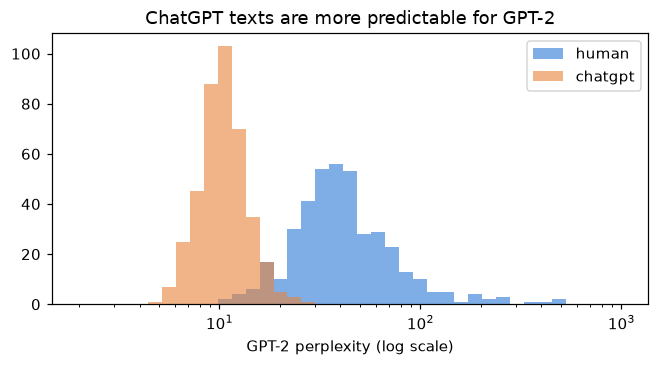

In [36]:
bins = np.logspace(0.3, 3, 40)
plt.figure(figsize=(7, 3.2))
plt.hist(test_sample[test_sample.y == 0].ppl, bins=bins, alpha=0.6, color=BLUE, label='human')
plt.hist(test_sample[test_sample.y == 1].ppl, bins=bins, alpha=0.6, color=ORANGE, label='chatgpt')
plt.xscale('log'); plt.xlabel('GPT-2 perplexity (log scale)'); plt.legend()
plt.title('ChatGPT texts are more predictable for GPT-2'); plt.show()

## 12. Results

### 12.1 All models side by side
**What this cell does:** collects the stored metrics into one table.

In [37]:
pd.DataFrame(results).T.round(3)

,Accuracy,F1,ROC-AUC
Length only,0.752,0.771,0.766
TF-IDF + logistic regression,0.987,0.987,0.999
PyTorch neural network,0.953,0.953,0.990
GPT-2 perplexity,0.954,0.953,0.991


**Conclusion:** all three detectors are far better than the length baseline. TF-IDF is the best so far;
GPT-2 works well without any training.

## 13. Test on unseen topics
A real detector meets topics it has never seen. We train TF-IDF + logistic regression on **4 topics**
and test it on **all answers of the 5th topic**, then compare with the score on a topic that *was* in training.

### 13.1 Leave one topic out
**What this cell does:** repeats training five times, each time leaving one topic out of training and testing on it.

In [38]:
rows = []
for topic in TOPICS:
    train_other_topics = train[train.topic != topic]
    unseen_topic = pairs[pairs.topic == topic]

    topic_vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=100_000,
                                       sublinear_tf=True, token_pattern=r"(?u)\b\w+\b|[^\w\s]")
    topic_model = LogisticRegression(C=4, max_iter=2000)
    topic_model.fit(topic_vectorizer.fit_transform(train_other_topics.text_clean), train_other_topics.y)
    f1_unseen = f1_score(unseen_topic.y, topic_model.predict(topic_vectorizer.transform(unseen_topic.text_clean)))

    seen_topic_test = test[test.topic == topic]
    f1_seen = f1_score(seen_topic_test.y, tfidf_model.predict(vectorizer.transform(seen_topic_test.text_clean)))

    rows.append({'topic': topic, 'F1 seen in training': f1_seen, 'F1 unseen topic': f1_unseen})

unseen = pd.DataFrame(rows).set_index('topic').round(3)
unseen['drop'] = unseen['F1 seen in training'] - unseen['F1 unseen topic']
unseen

,F1 seen in training,F1 unseen topic,drop
topic,,,
finance,0.994,0.977,0.017
medicine,1.000,0.993,0.007
open_qa,0.939,0.849,0.090
reddit_eli5,0.991,0.860,0.131
wiki_csai,0.955,0.875,0.080


### 13.2 Chart
**What this cell does:** shows the F1 on a seen topic next to the F1 on the same topic when it was unseen.

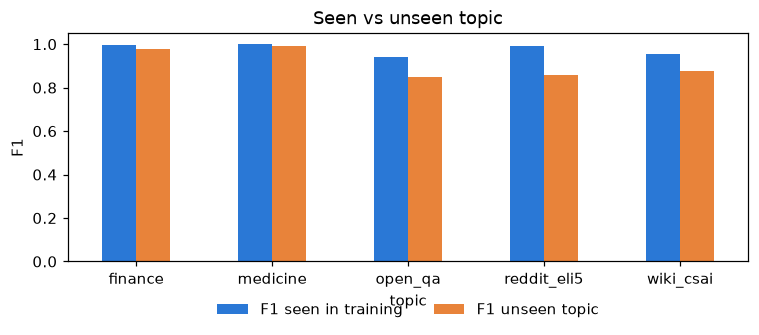

In [39]:
unseen[['F1 seen in training', 'F1 unseen topic']].plot.bar(color=[BLUE, ORANGE], figsize=(7, 3.2), rot=0)
plt.ylim(0, 1.05); plt.ylabel('F1'); plt.title('Seen vs unseen topic')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
plt.tight_layout(); plt.show()

**Conclusion:** the score drops on every unseen topic (up to 13 points on Reddit). The model partly learns topic words,
not only ChatGPT style. Improving this is the goal of the next stage (fine-tuning the RoBERTa transformer).

## 14. Extra — how ChatGPT style differs from human style
Guo et al. (2023) describe ChatGPT as formal, using many linking words, and humans as more personal with a richer vocabulary.
We measure four simple style features on our data.

### 14.1 Style features
**What this cell does:** four functions: (1) linking words per 100 words, (2) vocabulary richness (share of different words in windows of 50 words), (3) the word "I"/"my" per 100 words, (4) how much sentence length varies.

In [40]:
LINKING_WORDS = ['however', 'additionally', 'furthermore', 'moreover', 'in general', 'generally', 'overall', 'firstly',
                 'secondly', 'finally', 'in addition', 'therefore', 'for example', 'on the other hand', 'it is important',
                 'in summary', 'ultimately', 'typically', 'it is also']

def get_words(text):
    return re.findall(r"[A-Za-z']+", text.lower())

def linking_words_per_100(text):
    lower, n = text.lower(), max(len(get_words(text)), 1)
    found = sum(len(re.findall(r'\b' + re.escape(w) + r'\b', lower)) for w in LINKING_WORDS)
    return found * 100 / n

def vocabulary_richness(text, window=50):
    words = get_words(text)
    if len(words) <= window:
        return len(set(words)) / max(len(words), 1)
    scores = [len(set(words[i:i + window])) / window for i in range(0, len(words) - window + 1, 5)]
    return float(np.mean(scores))

def first_person_per_100(text):
    lower, n = text.lower(), max(len(get_words(text)), 1)
    return len(re.findall(r"\bi\b|\bi'm\b|\bi've\b|\bmy\b", lower)) * 100 / n

def sentence_length_variation(text):
    sentences = [s for s in re.split(r'(?<=[.!?])\s+', text) if re.search(r"[A-Za-z']+", s)]
    lengths = [len(get_words(s)) for s in sentences] or [len(get_words(text))]
    return float(np.std(lengths))

### 14.2 Compare human and ChatGPT
**What this cell does:** computes the four features for every answer and shows the average for each author.

In [41]:
style = pd.DataFrame({
    'linking words per 100 words': pairs.text_clean.apply(linking_words_per_100),
    'vocabulary richness': pairs.text_clean.apply(vocabulary_richness),
    '"I" / "my" per 100 words': pairs.text_clean.apply(first_person_per_100),
    'sentence-length variation': pairs.text_clean.apply(sentence_length_variation),
    'label': pairs.label,
})
style_means = style.groupby('label').mean().T.round(3)
style_means

label,chatgpt,human
linking words per 100 words,0.798,0.241
vocabulary richness,0.748,0.816
"""I"" / ""my"" per 100 words",0.131,0.984
sentence-length variation,7.192,7.231


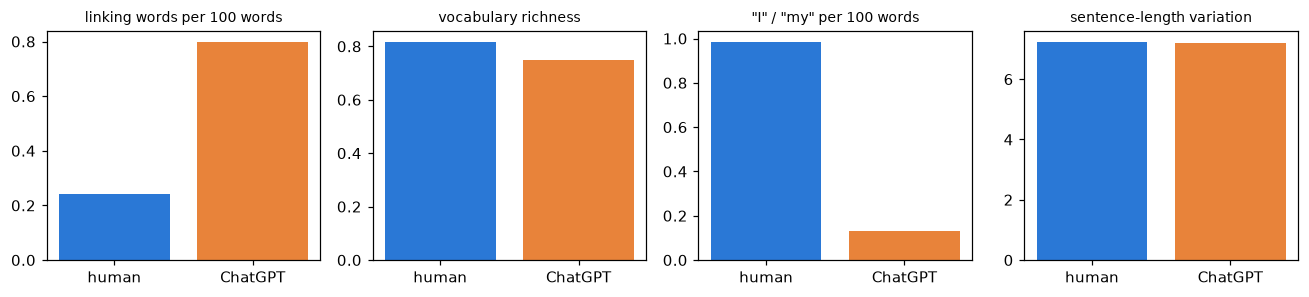

In [42]:
fig, axes = plt.subplots(1, 4, figsize=(12, 2.8))
for ax, feature in zip(axes, style_means.index):
    ax.bar(['human', 'ChatGPT'], [style_means.loc[feature, 'human'], style_means.loc[feature, 'chatgpt']], color=[BLUE, ORANGE])
    ax.set_title(feature, fontsize=9)
plt.tight_layout(); plt.show()

**Conclusion:** ChatGPT uses many more linking words; humans have a richer vocabulary and write "I" more often —
the same picture as described by Guo et al. (2023).

---
### Summary
1. HC3 contains a formatting trick that a one-line rule can exploit — we removed it by cleaning.
2. Three detectors (TF-IDF, a PyTorch network and GPT-2 perplexity) clearly beat the length baseline.
3. Quality drops on unseen topics — the next stage fine-tunes the RoBERTa transformer to improve generalisation.